# TIB P4e: faithfulness families and scoring cost on Colab T4

Pre-registered checks (`crossfamily_criteria.json`): which entailment-based faithfulness families
separate source-extract summaries from off-topic and corrupted ones, whether the families agree
with each other, and what scoring costs on a T4. Uses 60 train sources x 5 mechanically built
summaries (300 summaries). No reference text and no generation model. Only published packages
are used; nothing here is a self-made metric.

**Choose a T4 GPU runtime.** Inputs (private; TIB source use is local/private/noncommercial): `canonical_records.jsonl.gz` and the code bundle zip,
in Drive `MyDrive/TIB_P4E_261022/` on Colab, or the repository paths when run locally. The third-party packages are installed
from their public repositories at run time; the installed versions and checkpoint names are written
to the receipt and become the pins. This notebook was written against the packages' documented APIs
and has not been executed yet: a family that fails to load is reported, not replaced.

In [1]:
import hashlib, json, platform, subprocess, sys, time, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/TIB_P4E_261022")  # private folder with the two input files
    ROOT = Path("/content/p4e"); ROOT.mkdir(exist_ok=True)
    with zipfile.ZipFile(DRIVE_DIR / "tib-p4e-code-261022-v1.zip") as bundle:
        bundle.extractall(ROOT)
    RECORDS_PATH = DRIVE_DIR / "canonical_records.jsonl.gz"
    OUT_DIR = DRIVE_DIR / "results"
else:
    here = Path.cwd()
    ROOT = next(p for p in [here, *here.parents] if (p / "experiments/scripts/tib_faithfulness_cost.py").exists())
    RECORDS_PATH = ROOT / "research-data/tib-qualification-261019-1703/eda/canonical_records.jsonl.gz"
    OUT_DIR = ROOT / "experiments/outputs/tib-p4e-261022"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))
assert RECORDS_PATH.exists(), f"Missing input: {RECORDS_PATH}"

CRITERIA = ROOT / "experiments/registry/protocols/tib-reference-free-multilength-261022-v1/crossfamily_criteria.json"
EXPECTED_CRITERIA_SHA256 = "71e231b7bd6165dbe4078cf7a3e41a7607af045fd8107630f9c84e94aba29a54"
actual = hashlib.sha256(CRITERIA.read_bytes()).hexdigest()
assert actual == EXPECTED_CRITERIA_SHA256, (
    f"Criteria file hash {actual} differs from the notebook's {EXPECTED_CRITERIA_SHA256}. "
    "Usually the code zip in Drive is an older build: upload the latest tib-p4e-code-261022-v1.zip, "
    "replace the old one, then Runtime > Restart session and run again. Do not edit the criteria file.")
print("root:", ROOT)
print("records:", RECORDS_PATH)
print("criteria sha256 verified:", actual[:16], "...")

Mounted at /content/drive
root: /content/p4e
records: /content/drive/MyDrive/TIB_P4E_261022/canonical_records.jsonl.gz
criteria sha256 verified: 71e231b7bd6165db ...


In [2]:
import importlib.metadata as md_
def version(name):
    try:
        return md_.version(name)
    except md_.PackageNotFoundError:
        return None
ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(),
    "packages": {n: version(n) for n in ["nltk", "scikit-learn", "scipy", "numpy", "pandas", "torch", "transformers"]},
    "code_sha256": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in sorted((ROOT / "experiments/scripts").glob("tib_*.py"))},
}
print(json.dumps(ENVIRONMENT["packages"], indent=1))

{
 "nltk": "3.9.1",
 "scikit-learn": "1.6.1",
 "scipy": "1.16.3",
 "numpy": "2.1.3",
 "pandas": "2.2.3",
 "torch": "2.11.0+cu130",
 "transformers": "5.20.1"
}


In [3]:
import torch
assert torch.cuda.is_available(), "Select a GPU runtime (T4)"
GPU = torch.cuda.get_device_name(0)
print(GPU, torch.__version__)
ENVIRONMENT["gpu"] = GPU

Tesla T4 2.11.0+cu130


## Install the families
SummaC is skipped by default because it pins older libraries that can break the others; set
`TRY_SUMMAC = True` and run in a fresh runtime to try it. If pip changes numpy or transformers,
restart the runtime and run the notebook again from the top (the cells are repeatable).

In [4]:
TRY_SUMMAC = False
INSTALL_LOG = {}
def pip(label, *args):
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], capture_output=True, text=True)
    INSTALL_LOG[label] = {"returncode": result.returncode, "tail": (result.stderr or result.stdout)[-400:]}
    print(label, "ok" if result.returncode == 0 else "FAILED")
    if result.returncode:
        print("   ", INSTALL_LOG[label]["tail"])
pip("AlignScore", "git+https://github.com/yuh-zha/AlignScore.git")
if INSTALL_LOG["AlignScore"]["returncode"]:
    # AlignScore pins torch<2, which Colab cannot satisfy; try the package without its pins.
    pip("AlignScore-no-deps", "--no-deps", "git+https://github.com/yuh-zha/AlignScore.git")
    pip("AlignScore-runtime-deps", "pytorch-lightning", "sentencepiece")
pip("spacy-model", "spacy")
subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], capture_output=True)
pip("MiniCheck", "minicheck @ git+https://github.com/Liyan06/MiniCheck.git@main")
import nltk  # recent NLTK needs punkt_tab, which MiniCheck does not download
for resource in ("punkt", "punkt_tab"):
    nltk.download(resource, quiet=True)
if TRY_SUMMAC:
    pip("SummaC", "summac")
else:
    INSTALL_LOG["SummaC"] = {"skipped": True}

AlignScore FAILED
    ,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 1.26.0 Requires-Python <3.13,>=3.9; 1.26.1 Requires-Python <3.13,>=3.9
ERROR: Could not find a version that satisfies the requirement torch<2,>=1.12.1 (from alignscore) (from versions: 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0, 2.12.0, 2.12.1, 2.13.0, 2.14.0, 2.14.1)
ERROR: No matching distribution found for torch<2,>=1.12.1

AlignScore-no-deps ok
AlignScore-runtime-deps ok
spacy-model ok
MiniCheck ok


## Build the 300 summaries

In [5]:
import random, statistics
from experiments.scripts import tib_summary_constructors as build
from experiments.scripts import tib_faithfulness_cost as fc
criteria = fc.load_criteria()
records = build.load_train_sources(RECORDS_PATH)
full_sample = build.draw_sample(records, 70)
subset = fc.select_subset(full_sample, 20)
ROWS = fc.build_rows(subset, full_sample, criteria["data"]["budget_view_words"], 20261022)
print(len(records), "train sources,", len(subset), "records,", len(ROWS), "summaries")

7159 train sources, 60 records, 300 summaries


## Score with each family
The first three summaries of each family are warm-up and excluded from the timing.

In [6]:
families, load_errors = fc.load_families(["AlignScore", "MiniCheck"] + (["SummaC"] if TRY_SUMMAC else []))
print("available:", list(families)); print("unavailable:", load_errors)
import traceback
SCORES, TIMING, FAMILY_INFO, ROW_ERRORS = {}, {}, {}, {}
for name, (score_fn, info) in families.items():
    torch.cuda.reset_peak_memory_stats()
    scores, times, errors = [], [], 0
    for i, row in enumerate(ROWS):
        if i == 5 and errors == 5:
            print(name, "failed on the first 5 summaries; stopping this family. First error:")
            print(ROW_ERRORS[name])
            scores += [None] * (len(ROWS) - len(scores)); break
        torch.cuda.synchronize(); t0 = time.perf_counter()
        try:
            value = score_fn(row["source"], row["summary"])
        except Exception as exc:
            value, errors = None, errors + 1
            ROW_ERRORS.setdefault(name, traceback.format_exc()[-1500:])
        torch.cuda.synchronize(); elapsed = time.perf_counter() - t0
        scores.append(value)
        if i >= 3 and value is not None:
            times.append(elapsed)
    SCORES[name] = scores
    FAMILY_INFO[name] = info
    TIMING[name] = {"seconds_per_summary": statistics.median(times) if times else None,
                    "mean_seconds": statistics.fmean(times) if times else None,
                    "peak_vram_gib": torch.cuda.max_memory_allocated() / 2**30,
                    "row_errors": errors}
    print(name, TIMING[name])

config.json:   0%|          | 0.00/890 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/75.0 [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

available: ['MiniCheck']
unavailable: {'AlignScore': "ImportError: cannot import name 'AdamW' from 'transformers' (/usr/local/lib/python3.13/dist-packages/transformers/__init__.py)"}




Evaluating:   0%|          | 0/12 [00:00<?, ?it/s]

Evaluating:   8%|▊         | 1/12 [00:01<00:18,  1.69s/it]

Evaluating:  17%|█▋        | 2/12 [00:02<00:09,  1.03it/s]

Evaluating:  25%|██▌       | 3/12 [00:02<00:06,  1.35it/s]

Evaluating:  33%|███▎      | 4/12 [00:03<00:04,  1.60it/s]

Evaluating:  42%|████▏     | 5/12 [00:03<00:03,  1.78it/s]

Evaluating:  50%|█████     | 6/12 [00:03<00:03,  1.88it/s]

Evaluating:  58%|█████▊    | 7/12 [00:04<00:02,  1.97it/s]

Evaluating:  67%|██████▋   | 8/12 [00:04<00:02,  1.94it/s]

Evaluating:  75%|███████▌  | 9/12 [00:05<00:01,  1.99it/s]

Evaluating:  83%|████████▎ | 10/12 [00:05<00:00,  2.15it/s]

Evaluating:  92%|█████████▏| 11/12 [00:06<00:00,  2.23it/s]

Evaluating: 100%|██████████| 12/12 [00:06<00:00,  1.80it/s]


Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|█         | 1/9 [00:00<00:03,  2.65it/s]

Evaluating:  22%|██▏       | 2/9 [00:00<00:02,  2.56it/s]

Evaluating:  33%|███▎      | 3/9 [00:01<00:02,  2.48i

MiniCheck {'seconds_per_summary': 11.648462913000003, 'mean_seconds': 15.623915582464631, 'peak_vram_gib': 1.6805243492126465, 'row_errors': 0}


## Analysis

In [7]:
timing_ok = {k: v for k, v in TIMING.items() if v["seconds_per_summary"]}
analysis = fc.analyze(ROWS, SCORES, criteria, timing_ok)
print(json.dumps(analysis, indent=1)[:5000])

{
 "per_family": {
  "MiniCheck": {
   "G1_auroc": 0.9898148148148148,
   "G1_pass": true,
   "G2_share": 1.0,
   "G2_pass": true,
   "scored": 300,
   "total": 300,
   "cost": {
    "summaries": 12000,
    "seconds_per_summary": 11.648462913000003,
    "projected_gpu_hours": 38.82820971000001
   },
   "timing": {
    "seconds_per_summary": 11.648462913000003,
    "mean_seconds": 15.623915582464631,
    "peak_vram_gib": 1.6805243492126465,
    "row_errors": 0
   }
  }
 },
 "G3_cross_family": {
  "pass": null,
  "note": "fewer than two families ran"
 },
 "admissible_pending_cost_approval": [
  "MiniCheck"
 ]
}


In [8]:
receipt = {
    "schema_version": 1, "criteria_id": criteria["criteria_id"],
    "criteria_sha256": EXPECTED_CRITERIA_SHA256, "records": len(subset), "summaries": len(ROWS),
    "reference_text_used": False, "model_outputs_used": False,
    "environment": ENVIRONMENT, "install_log": INSTALL_LOG,
    "families": FAMILY_INFO, "unavailable": load_errors, "row_errors": ROW_ERRORS,
    "timing": TIMING, "analysis": analysis,
    "scores": [{"record_id": r["record_id"], "group": r["group"],
                **{n: SCORES[n][i] for n in SCORES}} for i, r in enumerate(ROWS)],
}
path = OUT_DIR / "faithfulness_crossfamily_receipt.json"
path.write_text(json.dumps(receipt, indent=2), encoding="utf-8")
print(path, hashlib.sha256(path.read_bytes()).hexdigest()[:16])

/content/drive/MyDrive/TIB_P4E_261022/results/faithfulness_crossfamily_receipt.json 8d3232e4e95ea7dc


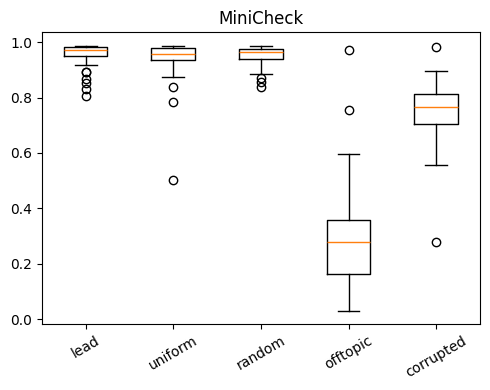

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, max(1, len(SCORES)), figsize=(5 * max(1, len(SCORES)), 4), squeeze=False)
for ax, (name, scores) in zip(axes[0], SCORES.items()):
    data = [[s for r, s in zip(ROWS, scores) if r["group"] == g and s is not None] for g in fc.ALL_GROUPS]
    ax.boxplot(data); ax.set_xticklabels(fc.ALL_GROUPS, rotation=30); ax.set_title(name)
fig.tight_layout(); fig.savefig(OUT_DIR / "faithfulness_by_group.png", dpi=130); plt.show()

## What to send back
`faithfulness_crossfamily_receipt.json` (scores only, no source text). It contains the installed
versions and checkpoints to pin, the per-family G1/G2 results, cross-family agreement (G3) and the
projected GPU hours for 12,000 summaries. You set the scoring budget after reading the projection.